# Disney Apriori Analysis (Revised)

This is the revised version of `Apriori_Analysis.ipynb`. Every code cell starts with a comment block that says **what changed and why**, using these tags:

| Tag | Meaning |
|---|---|
| `[KEPT]` | Same idea as your original notebook (sometimes cleaned up) |
| `[CHANGED]` | Your original logic, but fixed or generalized |
| `[ADDED]` | New step that was not in the original |
| `[REMOVED]` | Something from the original that is no longer here, and why |

**Summary of changes**

1. **One clean merge** (was two different merges: 223 rows in the saved CSV vs 226 rows used for Apriori). Titles are now matched on name **and release year (within 2 years)**, so remakes like *101 Dalmatians (1961 vs 1996)* or *Cinderella (2015 vs 1950)* no longer get the wrong genres. Duplicate rows are dropped.
2. **Apriori now grows until it stops by itself** (original stopped at k=3 by hand-coding; the lecture only stops at k=3 because its toy data runs out of itemsets). Your data has a frequent 4-itemset.
3. **Rules are generated for every frequent itemset**, using the lecture's "Candidates for Rules" restrictions (no empty sides, one-item consequent), then filtered by confidence and lift.
4. **Validation** (lecture "Evaluating Association Rules" slide): train/test split and a cross-check against `mlxtend`.
5. **Cross-feature rules** (rating, era, gross, IMDb score together with genres) to answer the professor's concern about depth.
6. **Visualizations** for the presentation.

In [1]:
# [CHANGED] Imports trimmed to what is actually used.
# [REMOVED] numpy, seaborn, KMeans, TransactionEncoder: they were imported but never used.
#           (KMeans is for clustering, which is not part of this Apriori notebook.)
# [ADDED]   mlxtend is now imported inside a try/except in the cross-check cell, only for validation.
import ast
from itertools import combinations
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)

In [2]:
# =====================  STEP 0: LOAD, MERGE, CLEAN  =====================
# [CHANGED] Your original notebook had TWO merges (cell 11 and cell 18) that did slightly different things:
#           cell 11 dropped rows with missing numbers (223 rows) and saved the CSV,
#           cell 18 did not drop them (226 rows) and was used for Apriori.
#           Now there is ONE merge, and its result is used for everything (Apriori + regression later).
DATA_DIR = "Datasets"          # change this if your CSVs live somewhere else
df_disney = pd.read_csv(f"{DATA_DIR}/disney_movies.csv")
df_titles = pd.read_csv(f"{DATA_DIR}/titles.csv")

# [KEPT] Normalize titles so "Aladdin " and "aladdin" match.
df_disney["clean_title"] = df_disney["movie_title"].str.strip().str.lower()
df_titles["clean_title"] = df_titles["title"].str.strip().str.lower()

# [ADDED] titles.csv also contains TV shows. We only want movies.
df_titles = df_titles[df_titles["type"] == "MOVIE"]

# [ADDED] Year of release on the Disney side, so we can compare it with titles.csv.
df_disney["disney_year"] = pd.to_datetime(df_disney["release_date"]).dt.year

# [CHANGED] Original: de-duplicated titles.csv by "highest imdb_votes" BEFORE merging.
#           Problem: for remakes (e.g. The Jungle Book 1967 / 1994 / 2016) the most-voted
#           entry is usually the newest remake, so old films got the wrong genres.
#           Now: merge on title first, then keep only matches whose years are close.
merged = df_disney.merge(
    df_titles[["clean_title", "release_year", "genres", "runtime", "imdb_score",
               "imdb_votes", "tmdb_popularity", "age_certification"]],
    on="clean_title", how="inner")
n_raw = len(merged)

# [ADDED] Year check: keep the match only if the two release years are within 2 years.
merged["year_gap"] = (merged["disney_year"] - merged["release_year"]).abs()
merged = merged[merged["year_gap"] <= 2]
n_year = len(merged)

# [ADDED] If a Disney row still matches several titles.csv rows, keep the closest year (then most votes),
#         and make sure each Disney film appears only once.
merged = (merged.sort_values(["year_gap", "imdb_votes"], ascending=[True, False])
                .drop_duplicates(["movie_title", "release_date"])
                .reset_index(drop=True))
n_dedup = len(merged)

# [KEPT] Drop rows with missing numeric values (needed later for regression).
merged = merged.dropna(subset=["runtime", "imdb_score", "imdb_votes", "inflation_adjusted_gross"]).reset_index(drop=True)

# [KEPT] Turn the genres string "['animation', 'family']" into a real, sorted, unique list.
def parse_genres(g):
    if pd.isna(g):
        return []
    try:
        p = ast.literal_eval(g)
        return sorted(set(str(x).lower().strip() for x in p)) if isinstance(p, list) else [str(g).lower().strip()]
    except Exception:
        return [str(g).lower().strip()]

merged["genre_basket"] = merged["genres"].apply(parse_genres)

# [ADDED] Print how many rows were lost at each step, good for your "Data Preparation" slide.
print(f"Title matches before year check : {n_raw}")
print(f"After year check (<= 2 yrs)     : {n_year}   (removed {n_raw - n_year} wrong remake/duplicate matches)")
print(f"After de-duplicating            : {n_dedup}")
print(f"After dropping missing numbers  : {len(merged)}   <- final dataset used everywhere")

merged.to_csv("disney_combined_clean.csv", index=False)

Title matches before year check : 245
After year check (<= 2 yrs)     : 221   (removed 24 wrong remake/duplicate matches)
After de-duplicating            : 221
After dropping missing numbers  : 218   <- final dataset used everywhere


In [3]:
# =====================  TRANSACTIONS  =====================
# [CHANGED] Original built `transactions` from a second merge. Now it comes from the same clean dataset.
# [CHANGED] Each basket is a Python set (faster and simpler for the subset checks below).
transactions = [set(b) for b in merged["genre_basket"]]
N = len(transactions)
minsupp = 0.15        # [KEPT] same minimum support as your original notebook

print("Number of transactions (films):", N)
print("Average genres per film       :", round(sum(len(t) for t in transactions) / N, 2))

Number of transactions (films): 218
Average genres per film       : 3.77


In [4]:
# =====================  APRIORI FUNCTIONS  =====================
# [ADDED] A reusable support() function. Original repeated the same sum(...) / N line everywhere.
def support(itemset, tx):
    s = set(itemset)
    return sum(1 for t in tx if s.issubset(t)) / len(tx)      # lecture slide: |{t in T : IS subset t}| / |T|


# [CHANGED] Original had three copy-pasted cells (k=1, k=2, k=3) and stopped at k=3.
#           This ONE function repeats "build candidates -> compute support -> keep/drop"
#           until no itemset survives. That is exactly the lecture's stopping rule:
#           "Repeat until no itemsets with minimal support are found / a threshold for k is reached".
#           It also returns a dictionary of ALL frequent itemsets and their supports,
#           so rule generation does not need to recount anything.
def apriori_manual(tx, minsupp, verbose=True):
    frequent = {}                                   # frozenset(itemset) -> support
    all_items = sorted({i for t in tx for i in t})

    # ---- k = 1 ----  [KEPT] same logic as original Step 1
    rows, Lk = [], []
    for item in all_items:
        s = support({item}, tx)
        keep = s >= minsupp
        rows.append({"Itemset": "{" + item + "}", "Support": round(s, 3), "Status": "Keep" if keep else "Drop"})
        if keep:
            frequent[frozenset([item])] = s
            Lk.append(frozenset([item]))
    if verbose:
        print("=== Table k=1 ===");  print(pd.DataFrame(rows).to_string(index=False))

    # ---- k >= 2 ----
    k = 2
    while Lk:
        prev = set(Lk)
        items = sorted(set().union(*Lk))
        # [KEPT] Apriori property (original Step 3): a candidate is only built if ALL its (k-1)-subsets are frequent.
        # [CHANGED] Now applied at every k, not just k=3.
        cands = [frozenset(c) for c in combinations(items, k)
                 if all(frozenset(sub) in prev for sub in combinations(c, k - 1))]
        if not cands:
            if verbose:
                print(f"\nNo candidates for k={k} -> growing terminates.")
            break
        rows, Lk = [], []
        for c in cands:
            s = support(c, tx)
            keep = s >= minsupp
            rows.append({"Itemset": "{" + ", ".join(sorted(c)) + "}", "Support": round(s, 3), "Status": "Keep" if keep else "Drop"})
            if keep:
                frequent[c] = s
                Lk.append(c)
        if verbose:
            print(f"\n=== Table k={k} ===");  print(pd.DataFrame(rows).to_string(index=False))
        if not Lk:
            if verbose:
                print(f"\nNo itemset at k={k} reached minsupp -> growing terminates.")
            break
        k += 1
    return frequent

In [5]:
# =====================  RUN APRIORI ON GENRES  =====================
# [CHANGED] Replaces original cells "Step 1", "Step 2", "Step 3" (k=1,2,3).
#           The k=1..3 tables should match your old ones (apart from small changes caused by the cleaner merge).
#           NEW: a k=4 table appears because {animation, comedy, family, fantasy} has all four of its
#           3-item subsets frequent, so Apriori MUST test it.
frequent = apriori_manual(transactions, minsupp)

=== Table k=1 ===
        Itemset  Support Status
       {action}    0.266   Keep
    {animation}    0.362   Keep
       {comedy}    0.665   Keep
        {crime}    0.069   Drop
{documentation}    0.050   Drop
        {drama}    0.381   Keep
     {european}    0.069   Drop
       {family}    0.817   Keep
      {fantasy}    0.390   Keep
      {history}    0.037   Drop
       {horror}    0.028   Drop
        {music}    0.064   Drop
      {romance}    0.193   Keep
        {scifi}    0.188   Keep
        {sport}    0.101   Drop
     {thriller}    0.050   Drop
          {war}    0.014   Drop
      {western}    0.028   Drop

=== Table k=2 ===
             Itemset  Support Status
 {action, animation}    0.069   Drop
    {action, comedy}    0.128   Drop
     {action, drama}    0.060   Drop
    {action, family}    0.193   Keep
   {action, fantasy}    0.073   Drop
   {action, romance}    0.028   Drop
     {action, scifi}    0.106   Drop
 {animation, comedy}    0.284   Keep
  {animation, drama}  

In [6]:
# [ADDED] Quick summary of what survived at each level (good for one slide).
by_size = {}
for itemset, s in frequent.items():
    by_size.setdefault(len(itemset), []).append((sorted(itemset), round(s, 3)))
for k in sorted(by_size):
    print(f"k={k}: {len(by_size[k])} frequent itemset(s)")
print("\nLargest frequent itemset(s):")
for items, s in by_size[max(by_size)]:
    print("  ", items, "support =", s)

k=1: 8 frequent itemset(s)
k=2: 11 frequent itemset(s)
k=3: 5 frequent itemset(s)
k=4: 1 frequent itemset(s)

Largest frequent itemset(s):
   ['animation', 'comedy', 'family', 'fantasy'] support = 0.193


In [7]:
# =====================  LECTURE-STYLE SCORE TABLE (one itemset)  =====================
# [KEPT] Your original Step 4 / "Overview of Scores" table, which mirrors the lecture slide for ONE itemset,
#        including the empty-antecedent and empty-consequent rows (all 8 rules).
# [CHANGED] Rewritten as a function so you can call it on any itemset (not only {animation, comedy, fantasy}).
#           It also reuses support(), so the "if not ante" special cases are gone
#           (support of the empty set is automatically 1.0).
def lecture_table(target, tx):
    items = sorted(target)
    s_xy = support(items, tx)
    rows = []
    for r in range(0, len(items) + 1):              # antecedent size 0..n
        for ante in combinations(items, r):
            ante = set(ante); cons = set(items) - ante
            s_x, s_y = support(ante, tx), support(cons, tx)
            rows.append({
                "Rule": ("{" + ", ".join(sorted(ante)) + "}" if ante else "Ø") + " => " +
                        ("{" + ", ".join(sorted(cons)) + "}" if cons else "Ø"),
                "Confidence": round(s_xy / s_x, 2),
                "Lift": round(s_xy / (s_x * s_y), 2),
                "Leverage": round(s_xy - s_x * s_y, 2)})
    return pd.DataFrame(rows)

print("=== Overview of Scores for {animation, comedy, fantasy} ===")
print(lecture_table({"animation", "comedy", "fantasy"}, transactions).to_string(index=False))

=== Overview of Scores for {animation, comedy, fantasy} ===
                             Rule  Confidence  Lift  Leverage
Ø => {animation, comedy, fantasy}        0.19  1.00      0.00
 {animation} => {comedy, fantasy}        0.53  1.84      0.09
 {comedy} => {animation, fantasy}        0.29  1.24      0.04
 {fantasy} => {animation, comedy}        0.49  1.74      0.08
 {animation, comedy} => {fantasy}        0.68  1.74      0.08
 {animation, fantasy} => {comedy}        0.82  1.24      0.04
 {comedy, fantasy} => {animation}        0.67  1.84      0.09
{animation, comedy, fantasy} => Ø        1.00  1.00      0.00


In [8]:
# =====================  RULES FOR ALL FREQUENT ITEMSETS  =====================
# [CHANGED] Original generated rules for ONE itemset only. Now: every frequent itemset with 2+ items.
# [ADDED]   Lecture slide "Candidates for Rules": usually (1) no empty antecedent/consequent, (2) only ONE item as consequent.
#           The 8-rule table above is for learning; the table below is what you report as findings.
def generate_rules(frequent, single_consequent=True):
    rows = []
    for itemset, s_xy in frequent.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):                       # r >= 1 and r < n  -> no empty sides
            for ante in combinations(sorted(itemset), r):
                ante = frozenset(ante); cons = itemset - ante
                if single_consequent and len(cons) != 1:
                    continue
                # Apriori property guarantees ante and cons are frequent, so their support is already stored.
                s_x, s_y = frequent[ante], frequent[cons]
                rows.append({
                    "antecedent": ante, "consequent": cons,
                    "Rule": "{" + ", ".join(sorted(ante)) + "} => {" + ", ".join(sorted(cons)) + "}",
                    "Support": s_xy,
                    "Confidence": s_xy / s_x,                  # support(X u Y) / support(X)
                    "Lift": s_xy / (s_x * s_y),                # support(X u Y) / (support(X) * support(Y))
                    "Leverage": s_xy - s_x * s_y})             # support(X u Y) - support(X) * support(Y)
    return pd.DataFrame(rows).sort_values("Lift", ascending=False).reset_index(drop=True)

MIN_CONF, MIN_LIFT = 0.6, 1.2          # [ADDED] thresholds suggested in your Gemini/professor pipeline
all_rules = generate_rules(frequent)
rules_f = all_rules[(all_rules["Confidence"] >= MIN_CONF) & (all_rules["Lift"] >= MIN_LIFT)].reset_index(drop=True)

print(f"Rules generated: {len(all_rules)}   |   after filter (conf >= {MIN_CONF}, lift >= {MIN_LIFT}): {len(rules_f)}")
show = ["Rule", "Support", "Confidence", "Lift", "Leverage"]
print(rules_f[show].round(3).to_string(index=False))

# [ADDED] Why {family} is dangerous: it appears in ~80% of films, so "X => family" has high confidence but lift near 1.
print("\nRules that END in {family} (look at how low their lift is):")
print(all_rules[all_rules["consequent"] == frozenset(["family"])][show].round(3).to_string(index=False))

Rules generated: 41   |   after filter (conf >= 0.6, lift >= 1.2): 15
                                    Rule  Support  Confidence  Lift  Leverage
{comedy, family, fantasy} => {animation}    0.193       0.700 1.932     0.093
        {comedy, fantasy} => {animation}    0.193       0.667 1.840     0.088
        {family, fantasy} => {animation}    0.234       0.646 1.781     0.103
        {animation, comedy} => {fantasy}    0.193       0.677 1.737     0.082
{animation, comedy, family} => {fantasy}    0.193       0.677 1.737     0.082
                {animation} => {fantasy}    0.234       0.646 1.656     0.093
                {fantasy} => {animation}    0.234       0.600 1.656     0.093
        {animation, family} => {fantasy}    0.234       0.646 1.656     0.093
{animation, family, fantasy} => {comedy}    0.193       0.824 1.238     0.037
        {animation, fantasy} => {comedy}    0.193       0.824 1.238     0.037
{animation, comedy, fantasy} => {family}    0.193       1.000 1.225     

In [9]:
# =====================  VALIDATION (lecture: "Evaluating Association Rules")  =====================
# [ADDED] Lecture says: "Validate if rules hold on test data".
#         Mine rules on a random 70% of films (train), then check the same rules on the other 30% (test).
train_df = merged.sample(frac=0.7, random_state=42)
test_df = merged.drop(train_df.index)
train_tx = [set(b) for b in train_df["genre_basket"]]
test_tx = [set(b) for b in test_df["genre_basket"]]
print(f"Train films: {len(train_tx)}   Test films: {len(test_tx)}")

rules_train = generate_rules(apriori_manual(train_tx, minsupp, verbose=False))
rules_train = rules_train[(rules_train["Confidence"] >= MIN_CONF) & (rules_train["Lift"] >= MIN_LIFT)]

def eval_rule(ante, cons, tx):
    s_x, s_y, s_xy = support(ante, tx), support(cons, tx), support(ante | cons, tx)
    conf = s_xy / s_x if s_x > 0 else float("nan")
    lift = s_xy / (s_x * s_y) if s_x > 0 and s_y > 0 else float("nan")
    return conf, lift

rows = []
for _, r in rules_train.iterrows():
    c_te, l_te = eval_rule(r["antecedent"], r["consequent"], test_tx)
    rows.append({"Rule": r["Rule"], "Train conf": r["Confidence"], "Test conf": c_te,
                 "Train lift": r["Lift"], "Test lift": l_te,
                 "Holds on test?": "Yes" if (c_te >= MIN_CONF and l_te > 1.0) else "No"})
val = pd.DataFrame(rows)
print(val.round(2).to_string(index=False))
print("\nRules that hold on unseen test films:", (val["Holds on test?"] == "Yes").sum(), "of", len(val))

Train films: 153   Test films: 65
                                    Rule  Train conf  Test conf  Train lift  Test lift Holds on test?
{comedy, family, fantasy} => {animation}        0.67       0.76        1.75       2.49            Yes
        {comedy, fantasy} => {animation}        0.64       0.72        1.67       2.35            Yes
        {family, fantasy} => {animation}        0.62       0.71        1.61       2.32            Yes
        {animation, comedy} => {fantasy}        0.62       0.87        1.52       2.45            Yes
{animation, comedy, family} => {fantasy}        0.62       0.87        1.52       2.45            Yes
                {animation} => {fantasy}        0.61       0.75        1.51       2.12            Yes
        {animation, family} => {fantasy}        0.61       0.75        1.51       2.12            Yes
{animation, comedy, fantasy} => {family}        1.00       1.00        1.20       1.27            Yes
        {animation, fantasy} => {family}        

In [10]:
# =====================  CROSS-CHECK WITH mlxtend  =====================
# [ADDED] You imported mlxtend in the original notebook but never used it.
#         Use it as an independent check that your manual Apriori is correct.
#         If both give the same itemsets and supports, you can say so in your presentation.
try:
    from mlxtend.frequent_patterns import apriori as mlx_apriori
    all_items = sorted({i for t in transactions for i in t})
    onehot = pd.DataFrame([[item in t for item in all_items] for t in transactions], columns=all_items)
    fi = mlx_apriori(onehot, min_support=minsupp, use_colnames=True)
    mlx = {frozenset(row.itemsets): row.support for row in fi.itertuples()}
    same_sets = set(mlx) == set(frequent)
    max_diff = max(abs(mlx[k] - frequent[k]) for k in frequent) if same_sets else None
    print("Same frequent itemsets as mlxtend? ", same_sets)
    print("Max support difference            :", max_diff)
    print("Manual:", len(frequent), "itemsets | mlxtend:", len(mlx), "itemsets")
except ImportError:
    print("mlxtend not installed. Run:  pip install mlxtend   then re-run this cell.")

Same frequent itemsets as mlxtend?  True
Max support difference            : 0.0
Manual: 25 itemsets | mlxtend: 25 itemsets


In [11]:
# =====================  CROSS-FEATURE RULES  =====================
# [ADDED] Your professor's concern was that genre-only baskets are thin. The merged data lets us put MORE kinds
#         of items in each basket: genre + age rating + era + box-office level + IMDb score level.
#         Prefixes (genre:, rating:, era:, gross:, score:) stop different features from clashing.
# NOTE: continuous columns have to be binned. Here we use a simple median split (high = at or above the median).
med_gross = merged["inflation_adjusted_gross"].median()
med_score = merged["imdb_score"].median()

def make_basket(row):
    items = [f"genre:{g}" for g in row["genre_basket"]]
    if pd.notna(row["age_certification"]):
        items.append(f"rating:{row['age_certification']}")
    items.append(f"era:{(row['disney_year'] // 10) * 10}s")
    items.append("gross:high" if row["inflation_adjusted_gross"] >= med_gross else "gross:low")
    items.append("score:high" if row["imdb_score"] >= med_score else "score:low")
    return set(items)

tx_x = [make_basket(r) for _, r in merged.iterrows()]
minsupp_x = 0.10          # lower than 0.15 because there are many more distinct items now
freq_x = apriori_manual(tx_x, minsupp_x, verbose=False)
print(f"Frequent itemsets with cross-feature baskets (minsupp={minsupp_x}): {len(freq_x)}")

targets = {"gross:high", "gross:low", "score:high", "score:low"}
rules_x = generate_rules(freq_x)
rules_x = rules_x[rules_x["consequent"].apply(lambda c: next(iter(c)) in targets)]
rules_x = rules_x[(rules_x["Confidence"] >= MIN_CONF) & (rules_x["Lift"] >= MIN_LIFT)].reset_index(drop=True)
print(f"Rules predicting gross/score level (conf >= {MIN_CONF}, lift >= {MIN_LIFT}): {len(rules_x)}")
print(rules_x[["Rule", "Support", "Confidence", "Lift", "Leverage"]].head(15).round(3).to_string(index=False))

Frequent itemsets with cross-feature baskets (minsupp=0.1): 332
Rules predicting gross/score level (conf >= 0.6, lift >= 1.2): 159
                                                                                    Rule  Support  Confidence  Lift  Leverage
                       {era:1990s, genre:comedy, genre:family, rating:PG} => {score:low}    0.124       0.931 1.879     0.058
                   {genre:animation, genre:family, gross:high, rating:G} => {score:high}    0.147       0.941 1.865     0.068
                                 {genre:animation, gross:high, rating:G} => {score:high}    0.147       0.941 1.865     0.068
                                     {era:2000s, genre:family, gross:low} => {score:low}    0.101       0.917 1.850     0.046
     {genre:animation, genre:comedy, genre:family, gross:high, rating:G} => {score:high}    0.110       0.923 1.829     0.050
                   {genre:animation, genre:comedy, gross:high, rating:G} => {score:high}    0.110       0.923 1.8

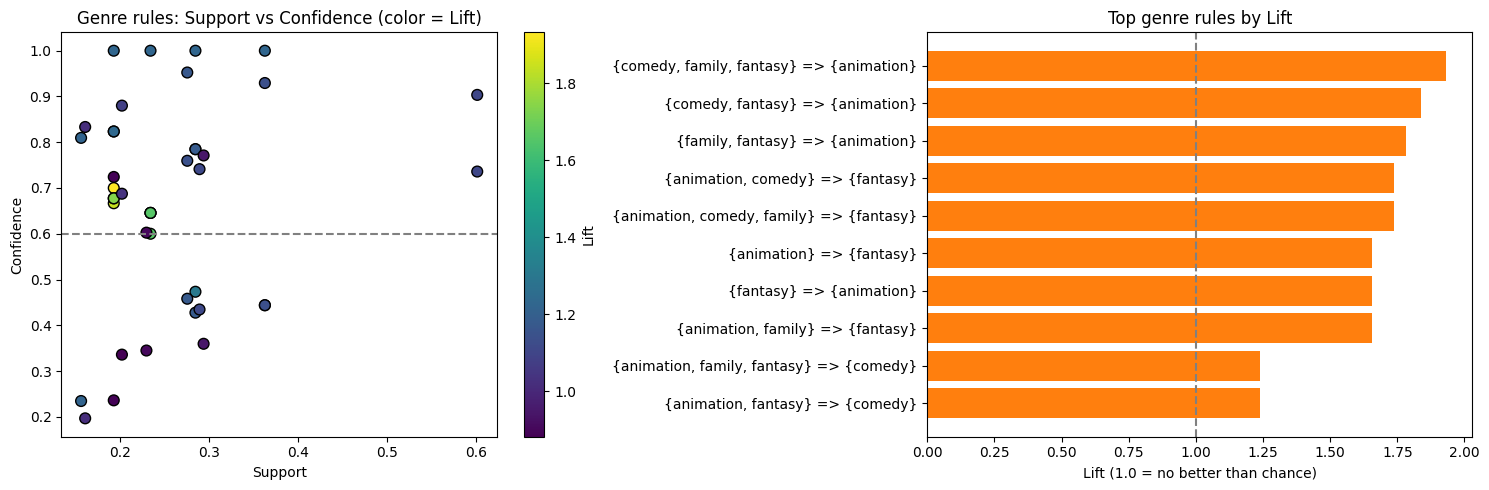

In [12]:
# =====================  VISUALIZATIONS  =====================
# [ADDED] Your original notebook had no charts. The grading rubric gives 15% for visualization.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# (1) Support vs Confidence, colored by Lift (all genre rules before filtering)
sc = axes[0].scatter(all_rules["Support"], all_rules["Confidence"], c=all_rules["Lift"], cmap="viridis", s=60, edgecolor="k")
axes[0].axhline(MIN_CONF, ls="--", c="gray")
axes[0].set_xlabel("Support"); axes[0].set_ylabel("Confidence"); axes[0].set_title("Genre rules: Support vs Confidence (color = Lift)")
fig.colorbar(sc, ax=axes[0], label="Lift")

# (2) Top rules by Lift
top = rules_f.head(10).iloc[::-1]
axes[1].barh(top["Rule"], top["Lift"], color="tab:orange")
axes[1].axvline(1.0, ls="--", c="gray")
axes[1].set_xlabel("Lift (1.0 = no better than chance)"); axes[1].set_title("Top genre rules by Lift")
plt.tight_layout()
plt.show()

## Talking points and caveats for your presentation

- **Why the merge fixes the professor's concern:** `disney_movies.csv` has 1 genre per film; `titles.csv` has about 3-4, so each film is a real basket.
- **Apriori stops by itself:** k=1 -> k=2 -> k=3 -> k=4 -> no more candidates.
- **Lift and leverage over confidence:** `{family}` is in most films, so rules ending in family look confident but add nothing beyond chance.
- **Selection bias:** `titles.csv` appears to be a streaming catalog, so only part of the 579 Disney films match. Your rules describe *those* films, not all Disney films.
- **Genre tags are noisy** (for example, a classic fairy tale tagged thriller), so treat the rules as patterns in the labels.
- **Regression is not in this notebook.** The saved `disney_combined_clean.csv` (same rows as above) is ready for it: log-transform gross and votes first.